# Sim gegen echtes Auto: abgespielte MPC-Befehle vergleichen

Vergleicht eine Sim-Aufnahme (MPC in Isaac Sim) mit der Aufnahme auf dem echten Auto,
auf dem genau diese `/ackermann_cmd`-Befehle mit `ros2 bag play` abgespielt wurden (offener Regelkreis).

**Zeitabgleich:** Die abgespielten Befehle tragen im Header noch ihren Sim-Zeitstempel.
Darüber wird jede echte Nachricht exakt dem passenden Sim-Zeitpunkt zugeordnet.
`t = 0` ist der erste Befehl mit Geschwindigkeit > 0.

**Verglichen wird:**
- Bahn (echte Bahn auf Startpunkt und Startrichtung der Sim gedreht und verschoben)
- Geschwindigkeit (Sim: `/odom`, echt: aus Vicon abgeleitet)
- Gierrate (Sim: `/odom`, echt: IMU und Vicon)
- Krümmung κ = Gierrate / Geschwindigkeit gegen Lenkbefehl: unabhängig davon, wie weit die Bahnen auseinanderlaufen

Ohne Regler laufen die Bahnen mit der Zeit auseinander. Aussagekräftig sind vor allem die ersten Sekunden
und die Kurven-Grössen (Gierrate, Krümmung, Geschwindigkeit).

## 1. Einstellungen
`PAIR` wählt das Paar aus der Liste. Pfade und Topic-Namen bei Bedarf anpassen.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from rosbags.highlevel import AnyReader
from rosbags.typesys import Stores, get_typestore

# ---- settings ---------------------------------------------------------------
DATA_DIR = Path(
    "/home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/"
    "sim-to-real-gap/stage-2-testing"
)
# (sim bag, real bag recorded while the sim commands were played back)
PAIRS = [
    (DATA_DIR / "data-sim-athena" / "sim_mpc_h12_ts008_run02",
     DATA_DIR / "data-real-athena" / "real_mpc_h12_ts008_run02"),
    (DATA_DIR / "data-sim-athena" / "sim_mpc_h12_ts008_run03",
     DATA_DIR / "data-real-athena" / "real_mpc_h12_ts008_run03"),
]
PAIR = 0

CMD_TOPIC = "/ackermann_cmd"
SIM_ODOM_TOPIC = "/odom"
VICON_TOPIC = "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker"
IMU_TOPIC = "/sensors/imu/raw"

WHEEL_BASE = 0.26  # m, for the kinematic curvature tan(delta) / L
COMPARE_S = 10.0  # s shown in the path / error plots after the alignment time
# align the real path onto the sim path at the start of this sim lap (1 = start of the run)
ALIGN_LAP = 2
SMOOTH_S = 0.1  # s, moving-average window for Vicon speed and yaw rate
MIN_SPEED = 0.2  # m/s, below this the curvature yaw_rate / speed is not used
# t = 0 at the first command above this speed (the MPC creeps with v + acc*dt from standstill)
CMD_START_SPEED = 0.05  # m/s
# Vicon samples implying a jump faster than this are treated as tracking dropouts
MAX_PLAUSIBLE_SPEED = 3.0  # m/s
# unit of the IMU angular velocity: "auto" (fit against Vicon), "rad/s" or "deg/s"
IMU_UNIT = "auto"
# yaw offset Vicon object -> car forward axis; None = estimate from the direction of motion
VICON_YAW_OFFSET = None

SIM_BAG, REAL_BAG = PAIRS[PAIR]
print(f"sim bag:  {SIM_BAG}")
print(f"real bag: {REAL_BAG}")

sim bag:  /home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/sim-to-real-gap/stage-2-testing/data-sim-athena/sim_mpc_h12_ts008_run02
real bag: /home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/sim-to-real-gap/stage-2-testing/data-real-athena/real_mpc_h12_ts008_run02


## 2. Hilfsfunktionen

In [2]:
def yaw_from_quaternion(q):
    """Return the yaw angle of a quaternion."""
    siny_cosp = 2.0 * (q.w * q.z + q.x * q.y)
    cosy_cosp = 1.0 - 2.0 * (q.y**2 + q.z**2)
    return math.atan2(siny_cosp, cosy_cosp)


def wrap_angle(angle):
    """Wrap an angle (or array of angles) to [-pi, pi]."""
    return np.arctan2(np.sin(angle), np.cos(angle))


def stamp_to_s(stamp):
    """builtin_interfaces/Time -> seconds."""
    return stamp.sec + stamp.nanosec * 1e-9


def read_bag(bag_path, topics):
    """Return {topic: [(bag_time_s, msg), ...]} for the requested topics."""
    typestore = get_typestore(Stores.ROS2_JAZZY)
    result = {}
    for topic in topics:
        result[topic] = []
    with AnyReader([bag_path], default_typestore=typestore) as reader:
        print(f"topics in {bag_path.name}:")
        for connection in reader.connections:
            print(f"  {connection.topic:60s} {connection.msgcount:7d} msgs")
        connections = []
        for connection in reader.connections:
            if connection.topic in topics:
                connections.append(connection)
        for connection, timestamp, rawdata in reader.messages(connections=connections):
            msg = reader.deserialize(rawdata, connection.msgtype)
            result[connection.topic].append((timestamp / 1e9, msg))
    for topic in topics:
        if len(result[topic]) == 0:
            print(f"!! topic {topic} not found or empty in {bag_path.name}")
    return result


def moving_average(values, window_samples):
    """Centered moving average; window in samples (>= 1)."""
    window_samples = max(1, int(window_samples))
    kernel = np.ones(window_samples) / window_samples
    padded = np.pad(values, (window_samples // 2, window_samples - 1 - window_samples // 2), mode="edge")
    return np.convolve(padded, kernel, mode="valid")


def hold_interp(t_query, t_source, values):
    """Zero-order hold: value of the last source sample at or before each query time."""
    index = np.searchsorted(t_source, t_query, side="right") - 1
    index = np.clip(index, 0, len(values) - 1)
    return values[index]


def command_time_offset(cmd_msgs):
    """Median of (bag time - header stamp) of the command messages.

    The replayed commands still carry their sim header stamp, so this offset maps
    any bag time of this bag onto the common command time (sim time).
    """
    differences = []
    for time_s, msg in cmd_msgs:
        differences.append(time_s - stamp_to_s(msg.header.stamp))
    return float(np.median(differences))

## 3. Aufnahmen lesen

In [3]:
sim = read_bag(SIM_BAG, [CMD_TOPIC, SIM_ODOM_TOPIC, "/tf"])
print()
real = read_bag(REAL_BAG, [CMD_TOPIC, VICON_TOPIC, IMU_TOPIC])

topics in sim_mpc_h12_ts008_run02:
  /ackermann_cmd                                                  8997 msgs
  /debug/waypoints                                                   1 msgs
  /clicked_point                                                     0 msgs
  /tf                                                             2543 msgs
  /events/write_split                                                0 msgs
  /clock                                                         15256 msgs
  /initialpose                                                       0 msgs
  /move_base_simple/goal                                             0 msgs
  /parameter_events                                                  0 msgs
  /odom                                                          15256 msgs
  /rosout                                                         9096 msgs
  /rtf                                                           15255 msgs
  /debug/current_waypoint                            

## 4. Gemeinsame Zeitachse

Beide Aufnahmen werden auf die **Befehlszeit** (Sim-Header-Zeitstempel) umgerechnet.
`t = 0` ist der erste Befehl mit `speed > 0.01`.

In [4]:
sim_offset = command_time_offset(sim[CMD_TOPIC])
real_offset = command_time_offset(real[CMD_TOPIC])
print(f"sim:  bag time - command stamp = {sim_offset:.3f} s (should be ~0)")
print(f"real: bag time - command stamp = {real_offset:.3f} s (wall clock vs sim clock)")

# commands (from the sim bag; the real bag must contain the same ones)
cmd_stamp = np.array([stamp_to_s(msg.header.stamp) for time_s, msg in sim[CMD_TOPIC]])
cmd_speed = np.array([msg.drive.speed for time_s, msg in sim[CMD_TOPIC]])
cmd_steer = np.array([msg.drive.steering_angle for time_s, msg in sim[CMD_TOPIC]])
order = np.argsort(cmd_stamp)  # sort by stamp (bag order can differ slightly)
cmd_stamp = cmd_stamp[order]
cmd_speed = cmd_speed[order]
cmd_steer = cmd_steer[order]

moving = np.nonzero(cmd_speed > CMD_START_SPEED)[0]
t0 = cmd_stamp[moving[0]]
print(f"first command above {CMD_START_SPEED} m/s at command time {t0:.3f} s")

t_cmd = cmd_stamp - t0

# check: are the same commands in the real bag?
real_cmd_stamp = np.array([stamp_to_s(msg.header.stamp) for time_s, msg in real[CMD_TOPIC]])
real_cmd_steer = np.array([msg.drive.steering_angle for time_s, msg in real[CMD_TOPIC]])
real_cmd_t = np.array([time_s for time_s, msg in real[CMD_TOPIC]]) - real_offset - t0
print(f"commands: sim {len(cmd_stamp)}, real {len(real_cmd_stamp)}")
playback_jitter = real_cmd_t - (real_cmd_stamp - t0)
print(
    f"playback jitter (arrival on the real car vs original spacing): "
    f"p95 {np.percentile(np.abs(playback_jitter), 95) * 1000:.1f} ms, "
    f"max {np.max(np.abs(playback_jitter)) * 1000:.1f} ms"
)

sim:  bag time - command stamp = 0.017 s (should be ~0)
real: bag time - command stamp = 1794758182.354 s (wall clock vs sim clock)
first command above 0.05 m/s at command time 60.883 s
commands: sim 8997, real 8997
playback jitter (arrival on the real car vs original spacing): p95 17.2 ms, max 5016.8 ms


## 5. Sim: Pose, Geschwindigkeit, Gierrate
Pose aus `/odom`, mit `World -> odom` aus `/tf` in World umgerechnet (wie im MPC-Node).

In [5]:
world_to_odom = None
for time_s, msg in sim["/tf"]:
    for transform in msg.transforms:
        if transform.header.frame_id == "World" and transform.child_frame_id == "odom":
            world_to_odom = (
                transform.transform.translation.x,
                transform.transform.translation.y,
                yaw_from_quaternion(transform.transform.rotation),
            )
            break
    if world_to_odom is not None:
        break
# fallback: enter the start pose by hand
# world_to_odom = (3.25, 5.4, -math.pi / 2)
print(f"sim World -> odom: {world_to_odom}")
odom_x0, odom_y0, odom_yaw0 = world_to_odom

sim_t, sim_x, sim_y, sim_psi, sim_v, sim_yaw_rate = [], [], [], [], [], []
for time_s, msg in sim[SIM_ODOM_TOPIC]:
    x_o = msg.pose.pose.position.x
    y_o = msg.pose.pose.position.y
    sim_t.append(time_s - sim_offset - t0)
    sim_x.append(odom_x0 + math.cos(odom_yaw0) * x_o - math.sin(odom_yaw0) * y_o)
    sim_y.append(odom_y0 + math.sin(odom_yaw0) * x_o + math.cos(odom_yaw0) * y_o)
    sim_psi.append(odom_yaw0 + yaw_from_quaternion(msg.pose.pose.orientation))
    sim_v.append(msg.twist.twist.linear.x)
    sim_yaw_rate.append(msg.twist.twist.angular.z)
sim_t = np.array(sim_t)
sim_x = np.array(sim_x)
sim_y = np.array(sim_y)
sim_psi = np.unwrap(np.array(sim_psi))
sim_v = np.array(sim_v)
sim_yaw_rate = np.array(sim_yaw_rate)
print(f"sim odom: {len(sim_t)} samples, {sim_t[0]:.1f} .. {sim_t[-1]:.1f} s")

sim World -> odom: (3.25, 5.4, -1.5707771464270195)
sim odom: 15256 samples, -12.6 .. 241.7 s


## 6. Echt: Vicon und IMU

- Geschwindigkeit und Gierrate aus Vicon: Ableitung der geglätteten Position bzw. des Winkels
- Gierrate zusätzlich aus der IMU (`angular_velocity.z`)
- Ist die Vicon-Objektachse nicht genau die Fahrtrichtung des Autos, wird der Versatz
  aus der Bewegungsrichtung geschätzt (`VICON_YAW_OFFSET = None`)

In [6]:
real_t = np.array([time_s for time_s, msg in real[VICON_TOPIC]]) - real_offset - t0
real_x = np.array([msg.pose.position.x for time_s, msg in real[VICON_TOPIC]])
real_y = np.array([msg.pose.position.y for time_s, msg in real[VICON_TOPIC]])
real_psi_raw = np.unwrap(np.array([yaw_from_quaternion(msg.pose.orientation) for time_s, msg in real[VICON_TOPIC]]))

# remove duplicate time stamps (gradient would divide by zero)
keep = np.concatenate(([True], np.diff(real_t) > 1e-6))
real_t = real_t[keep]
real_x = real_x[keep]
real_y = real_y[keep]
real_psi_raw = real_psi_raw[keep]

# Vicon dropouts: a jump faster than MAX_PLAUSIBLE_SPEED is not a real motion.
# Compare each sample with the last good one and replace bad ones by interpolation.
good = np.ones(len(real_t), dtype=bool)
last_good = 0
for i in range(1, len(real_t)):
    step = math.hypot(real_x[i] - real_x[last_good], real_y[i] - real_y[last_good])
    if step / (real_t[i] - real_t[last_good]) > MAX_PLAUSIBLE_SPEED:
        good[i] = False
    else:
        last_good = i
print(f"vicon dropouts removed: {np.sum(~good)} of {len(good)} samples")
real_x = np.interp(real_t, real_t[good], real_x[good])
real_y = np.interp(real_t, real_t[good], real_y[good])
real_psi_raw = np.interp(real_t, real_t[good], real_psi_raw[good])
vicon_rate = (len(real_t) - 1) / (real_t[-1] - real_t[0])
window = int(round(SMOOTH_S * vicon_rate))
print(f"vicon: {len(real_t)} samples, {vicon_rate:.0f} Hz, smoothing window {window} samples")

# velocity in World from the smoothed position
x_smooth = moving_average(real_x, window)
y_smooth = moving_average(real_y, window)
vx = np.gradient(x_smooth, real_t)
vy = np.gradient(y_smooth, real_t)
real_v = np.hypot(vx, vy)

# yaw offset between the Vicon object axis and the direction of motion (forward driving)
if VICON_YAW_OFFSET is None:
    fast = real_v > MIN_SPEED
    motion_dir = np.arctan2(vy[fast], vx[fast])
    difference = wrap_angle(motion_dir - real_psi_raw[fast])
    yaw_offset = math.atan2(np.mean(np.sin(difference)), np.mean(np.cos(difference)))
    print(f"estimated Vicon yaw offset: {yaw_offset:.3f} rad ({math.degrees(yaw_offset):.1f} deg)")
    if abs(yaw_offset) > 0.2:
        print("!! large offset: the Vicon object x axis is not the car forward axis")
else:
    yaw_offset = VICON_YAW_OFFSET
real_psi = real_psi_raw + yaw_offset

real_yaw_rate_vicon = moving_average(np.gradient(real_psi, real_t), window)

# IMU yaw rate
imu_t = np.array([time_s for time_s, msg in real[IMU_TOPIC]]) - real_offset - t0
imu_yaw_rate_raw = np.array([msg.angular_velocity.z for time_s, msg in real[IMU_TOPIC]])
imu_rate = (len(imu_t) - 1) / (imu_t[-1] - imu_t[0])
imu_yaw_rate = moving_average(imu_yaw_rate_raw, int(round(SMOOTH_S * imu_rate)))
print(f"imu:   {len(imu_t)} samples, {imu_rate:.0f} Hz")

# unit and sign: fit IMU = scale * Vicon where the car is turning
vicon_at_imu = np.interp(imu_t, real_t, real_yaw_rate_vicon)
# median of the ratio is robust against single spikes in either signal
turning = np.abs(vicon_at_imu) > 0.2
scale = float(np.median(imu_yaw_rate[turning] / vicon_at_imu[turning]))
print(f"IMU yaw rate / Vicon yaw rate (median) = {scale:.2f}")
if IMU_UNIT == "deg/s" or (IMU_UNIT == "auto" and abs(scale) > 20.0):
    print("-> IMU angular velocity is in deg/s, converting to rad/s")
    imu_yaw_rate = np.radians(imu_yaw_rate)
    scale = scale * math.pi / 180.0
if scale < 0:
    print("!! negative: the IMU z axis points down -> flipping the IMU yaw rate sign")
    imu_yaw_rate = -imu_yaw_rate
    scale = -scale
print(f"after correction: IMU / Vicon = {scale:.2f} (should be close to 1)")

vicon dropouts removed: 26 of 49558 samples
vicon: 49558 samples, 190 Hz, smoothing window 19 samples
estimated Vicon yaw offset: 1.556 rad (89.1 deg)
!! large offset: the Vicon object x axis is not the car forward axis
imu:   13026 samples, 50 Hz
IMU yaw rate / Vicon yaw rate (median) = 56.82
-> IMU angular velocity is in deg/s, converting to rad/s
after correction: IMU / Vicon = 0.99 (should be close to 1)


## 7. Bahnen ausrichten
Die echte Bahn wird so gedreht und verschoben, dass sie bei `t = 0` am selben Ort und in dieselbe Richtung startet wie die Sim-Bahn.

In [7]:
# ---- lap starts of the sim car: passes near its own start point -------------
start_x = np.interp(0.0, sim_t, sim_x)
start_y = np.interp(0.0, sim_t, sim_y)
distance_to_start = np.hypot(sim_x - start_x, sim_y - start_y)
lap_starts = [0.0]
was_far = False
for i in range(len(sim_t)):
    if sim_t[i] <= 0.0:
        continue
    if distance_to_start[i] > 1.0:
        was_far = True
    elif was_far and distance_to_start[i] < 0.3:
        # closest point of this passage within the next second
        passage = np.nonzero((sim_t >= sim_t[i]) & (sim_t <= sim_t[i] + 1.0))[0]
        closest = passage[np.argmin(distance_to_start[passage])]
        lap_starts.append(sim_t[closest])
        was_far = False
print("sim lap starts [s]: " + ", ".join(f"{t:.1f}" for t in lap_starts))
if len(lap_starts) > 1:
    print("sim lap times  [s]: " + ", ".join(f"{b - a:.1f}" for a, b in zip(lap_starts[:-1], lap_starts[1:])))

if ALIGN_LAP is not None and ALIGN_LAP <= len(lap_starts):
    t_align = lap_starts[ALIGN_LAP - 1]
else:
    t_align = 0.0
    print(f"!! lap {ALIGN_LAP} not found, aligning at t = 0")
print(f"aligning at t = {t_align:.2f} s (start of lap {ALIGN_LAP})")
print(
    f"speed at alignment: sim {np.interp(t_align, sim_t, sim_v):.2f} m/s, "
    f"real {np.interp(t_align, real_t, real_v):.2f} m/s"
)

sim_x0 = np.interp(t_align, sim_t, sim_x)
sim_y0 = np.interp(t_align, sim_t, sim_y)
sim_psi0 = np.interp(t_align, sim_t, sim_psi)
real_x0 = np.interp(t_align, real_t, real_x)
real_y0 = np.interp(t_align, real_t, real_y)
real_psi0 = np.interp(t_align, real_t, real_psi)

rotation = sim_psi0 - real_psi0
cos_r = math.cos(rotation)
sin_r = math.sin(rotation)
real_x_aligned = sim_x0 + cos_r * (real_x - real_x0) - sin_r * (real_y - real_y0)
real_y_aligned = sim_y0 + sin_r * (real_x - real_x0) + cos_r * (real_y - real_y0)
print(f"real path rotated by {math.degrees(rotation):.1f} deg and moved onto the sim pose at t = {t_align:.2f} s")

# position error on a common time grid
t_grid = np.arange(t_align, min(t_align + COMPARE_S, sim_t[-1], real_t[-1]), 0.01)
error = np.hypot(
    np.interp(t_grid, real_t, real_x_aligned) - np.interp(t_grid, sim_t, sim_x),
    np.interp(t_grid, real_t, real_y_aligned) - np.interp(t_grid, sim_t, sim_y),
)

sim lap starts [s]: 0.0, 14.0, 25.1, 36.2, 47.2, 58.3, 69.3, 80.4, 91.5, 102.5, 113.6, 124.7, 135.7, 146.8, 157.8, 168.9, 180.0, 191.0, 202.1, 213.2, 224.2, 235.3
sim lap times  [s]: 14.0, 11.0, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.0, 11.1, 11.1, 11.1, 11.1, 11.1
aligning at t = 14.05 s (start of lap 2)
speed at alignment: sim 1.00 m/s, real 0.94 m/s
real path rotated by -464.9 deg and moved onto the sim pose at t = 14.05 s


## 8. Kennzahlen

In [8]:
sim_start = sim_t[np.nonzero((sim_t > -1.0) & (sim_v > CMD_START_SPEED))[0][0]]
real_start = real_t[np.nonzero((real_t > -1.0) & (real_v > CMD_START_SPEED))[0][0]]
print("--- start ---")
print(f"sim moves (> {CMD_START_SPEED} m/s) at  {sim_start:6.2f} s")
print(f"real moves (> {CMD_START_SPEED} m/s) at {real_start:6.2f} s   -> real starts {real_start - sim_start:+.2f} s later")
print(f"command speed when the real car starts: {hold_interp(np.array([real_start]), t_cmd, cmd_speed)[0]:.3f} m/s")

print(f"\n--- position difference real vs sim after alignment at t = {t_align:.1f} s (open loop) ---")
for check_time in [1.0, 2.0, 5.0, 10.0]:
    if t_align + check_time <= t_grid[-1] + 0.02:
        print(f"after {check_time:4.1f} s: {np.interp(t_align + check_time, t_grid, error) * 100:6.1f} cm")

# speed while the command is above MIN_SPEED (skip the first second: start-up)
cmd_speed_at_sim = hold_interp(sim_t, t_cmd, cmd_speed)
cmd_speed_at_real = hold_interp(real_t, t_cmd, cmd_speed)
use_sim = (sim_t > 1.0) & (cmd_speed_at_sim > MIN_SPEED)
use_real = (real_t > 1.0) & (cmd_speed_at_real > MIN_SPEED)
print("\n--- speed (t > 1 s, command > MIN_SPEED) ---")
print(f"commanded mean: {cmd_speed[cmd_speed > MIN_SPEED].mean():.3f} m/s")
print(f"sim  measured:  {sim_v[use_sim].mean():.3f} m/s   (ratio to command "
      f"{np.mean(sim_v[use_sim] / cmd_speed_at_sim[use_sim]):.3f})")
print(f"real measured:  {real_v[use_real].mean():.3f} m/s   (ratio to command "
      f"{np.mean(real_v[use_real] / cmd_speed_at_real[use_real]):.3f})")

# curvature kappa = yaw rate / speed vs steering command
steer_at_sim = hold_interp(sim_t, t_cmd, cmd_steer)
steer_at_imu = hold_interp(imu_t, t_cmd, cmd_steer)
real_v_at_imu = np.interp(imu_t, real_t, real_v)
sim_kappa_mask = sim_v > MIN_SPEED
real_kappa_mask = (real_v_at_imu > MIN_SPEED) & (imu_t > 0.0)
sim_kappa = sim_yaw_rate[sim_kappa_mask] / sim_v[sim_kappa_mask]
real_kappa = imu_yaw_rate[real_kappa_mask] / real_v_at_imu[real_kappa_mask]

# linear fit kappa = gain * steering (through zero) for both
sim_gain = np.sum(steer_at_sim[sim_kappa_mask] * sim_kappa) / np.sum(steer_at_sim[sim_kappa_mask] ** 2)
real_gain = np.sum(steer_at_imu[real_kappa_mask] * real_kappa) / np.sum(steer_at_imu[real_kappa_mask] ** 2)
print("\n--- curvature per steering command (kappa = gain * delta) ---")
print(f"kinematic: {1.0 / WHEEL_BASE:.2f} 1/(m rad)   (tan(delta)/L for small delta)")
print(f"sim:       {sim_gain:.2f} 1/(m rad)")
print(f"real:      {real_gain:.2f} 1/(m rad)   (real / sim = {real_gain / sim_gain:.3f})")

--- start ---
sim moves (> 0.05 m/s) at    0.07 s
real moves (> 0.05 m/s) at   2.49 s   -> real starts +2.42 s later
command speed when the real car starts: 0.437 m/s

--- position difference real vs sim after alignment at t = 14.0 s (open loop) ---
after  1.0 s:   13.8 cm
after  2.0 s:   31.6 cm
after  5.0 s:  154.2 cm
after 10.0 s:  228.0 cm

--- speed (t > 1 s, command > MIN_SPEED) ---
commanded mean: 0.989 m/s
sim  measured:  0.992 m/s   (ratio to command 1.002)
real measured:  0.952 m/s   (ratio to command 0.958)

--- curvature per steering command (kappa = gain * delta) ---
kinematic: 3.85 1/(m rad)   (tan(delta)/L for small delta)
sim:       3.80 1/(m rad)
real:      4.71 1/(m rad)   (real / sim = 1.241)


## 9. Plots

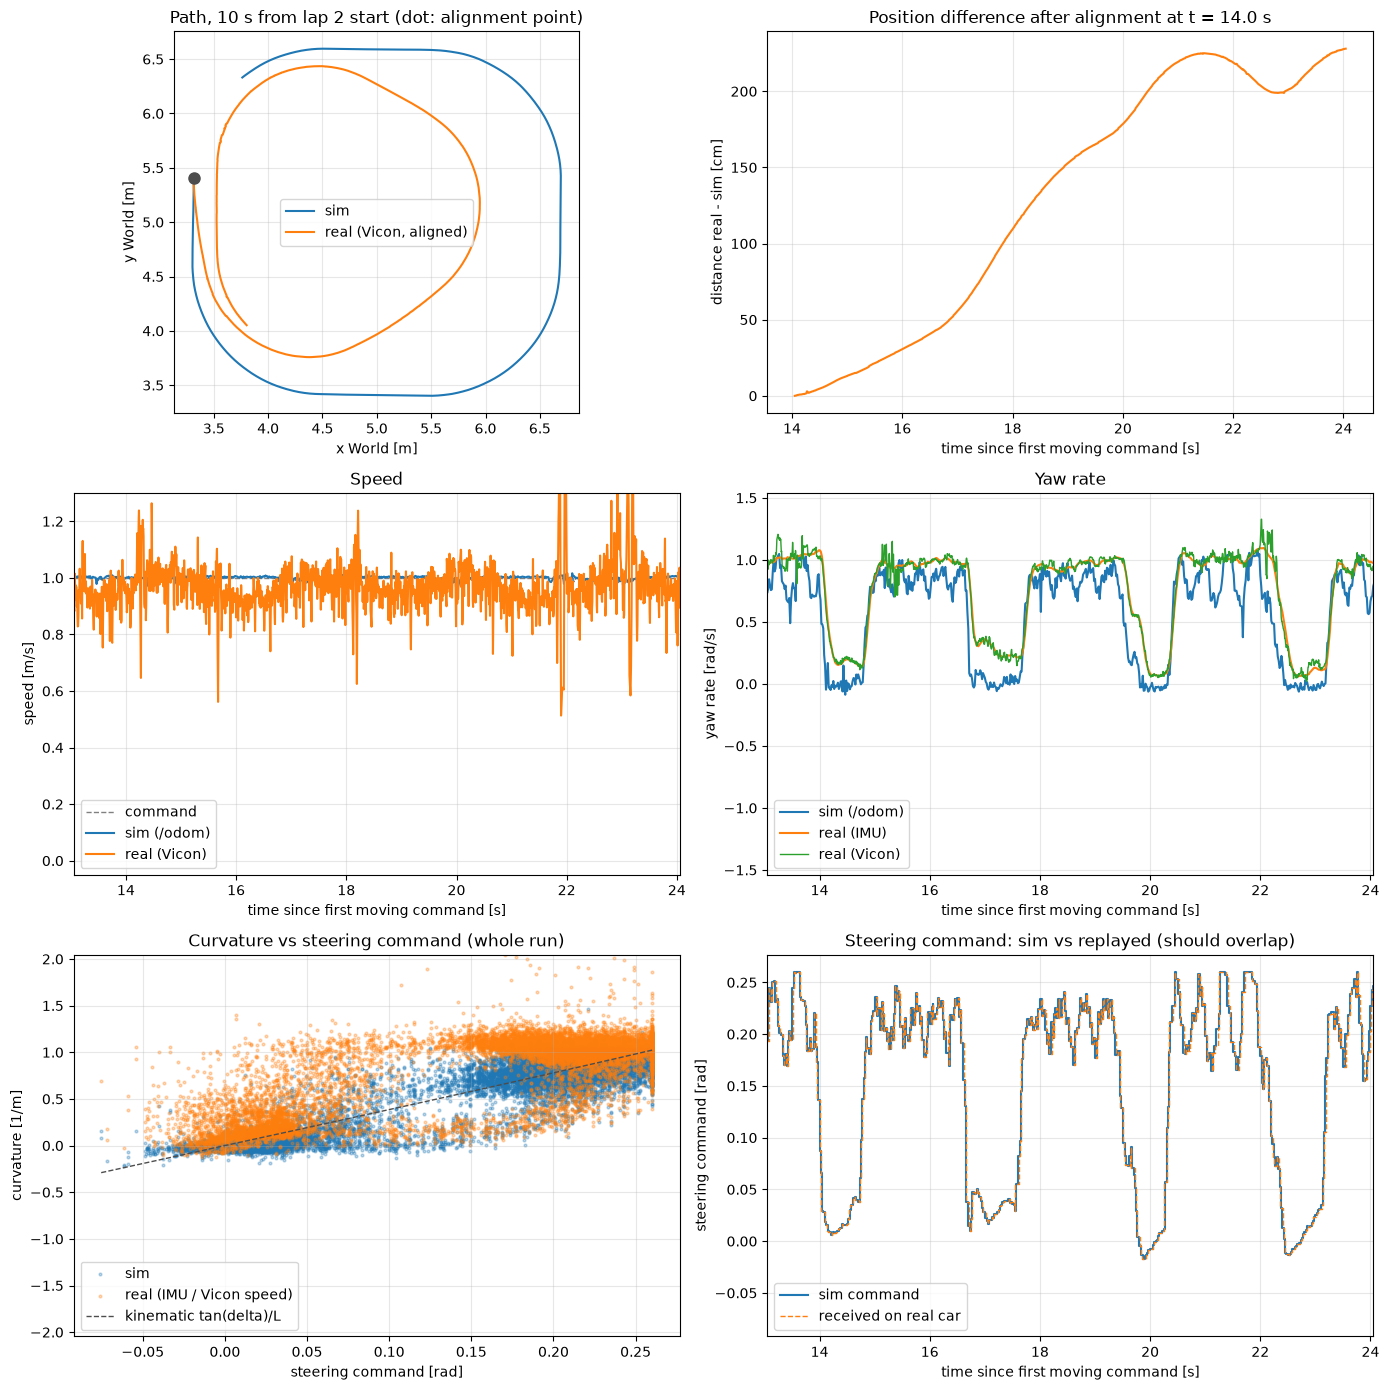

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
window_sim = (sim_t >= t_align) & (sim_t <= t_align + COMPARE_S)
window_real = (real_t >= t_align) & (real_t <= t_align + COMPARE_S)
x_window = (t_align - 1.0, t_align + COMPARE_S)

ax = axes[0, 0]
ax.plot(sim_x[window_sim], sim_y[window_sim], color="tab:blue", linewidth=1.5, label="sim")
ax.plot(real_x_aligned[window_real], real_y_aligned[window_real], color="tab:orange", linewidth=1.5, label="real (Vicon, aligned)")
ax.plot(sim_x0, sim_y0, "o", color="0.3", markersize=8)
ax.set_aspect("equal")
ax.set_xlabel("x World [m]")
ax.set_ylabel("y World [m]")
ax.set_title(f"Path, {COMPARE_S:.0f} s from lap {ALIGN_LAP} start (dot: alignment point)")
ax.legend()

ax = axes[0, 1]
ax.plot(t_grid, error * 100, color="tab:orange", linewidth=1.5)
ax.set_xlabel("time since first moving command [s]")
ax.set_ylabel("distance real - sim [cm]")
ax.set_title(f"Position difference after alignment at t = {t_align:.1f} s")

ax = axes[1, 0]
ax.plot(t_cmd, cmd_speed, color="0.5", linestyle="--", linewidth=1, drawstyle="steps-post", label="command")
ax.plot(sim_t, sim_v, color="tab:blue", linewidth=1.5, label="sim (/odom)")
ax.plot(real_t, real_v, color="tab:orange", linewidth=1.5, label="real (Vicon)")
ax.set_xlim(*x_window)
ax.set_xlabel("time since first moving command [s]")
ax.set_ylabel("speed [m/s]")
ax.set_ylim(-0.05, 1.3 * cmd_speed.max())
ax.set_title("Speed")
ax.legend()

ax = axes[1, 1]
ax.plot(sim_t, sim_yaw_rate, color="tab:blue", linewidth=1.5, label="sim (/odom)")
ax.plot(imu_t, imu_yaw_rate, color="tab:orange", linewidth=1.5, label="real (IMU)")
ax.plot(real_t, real_yaw_rate_vicon, color="tab:green", linewidth=1, label="real (Vicon)")
ax.set_xlim(*x_window)
ax.set_xlabel("time since first moving command [s]")
ax.set_ylabel("yaw rate [rad/s]")
yaw_limit = 1.3 * max(np.percentile(np.abs(sim_yaw_rate), 99.5), np.percentile(np.abs(real_yaw_rate_vicon), 99.5))
ax.set_ylim(-yaw_limit, yaw_limit)
ax.set_title("Yaw rate")
ax.legend()

ax = axes[2, 0]
ax.scatter(steer_at_sim[sim_kappa_mask], sim_kappa, s=4, color="tab:blue", alpha=0.3, label="sim")
ax.scatter(steer_at_imu[real_kappa_mask], real_kappa, s=4, color="tab:orange", alpha=0.3, label="real (IMU / Vicon speed)")
delta_line = np.linspace(cmd_steer.min(), cmd_steer.max(), 50)
ax.plot(delta_line, np.tan(delta_line) / WHEEL_BASE, color="0.3", linestyle="--", linewidth=1, label="kinematic tan(delta)/L")
ax.set_xlabel("steering command [rad]")
ax.set_ylabel("curvature [1/m]")
kappa_limit = 2.0 * np.max(np.abs(np.tan(delta_line))) / WHEEL_BASE
ax.set_ylim(-kappa_limit, kappa_limit)
ax.set_title("Curvature vs steering command (whole run)")
ax.legend()

ax = axes[2, 1]
ax.plot(t_cmd, cmd_steer, color="tab:blue", linewidth=1.5, drawstyle="steps-post", label="sim command")
ax.plot(real_cmd_t, real_cmd_steer, color="tab:orange", linewidth=1, linestyle="--", drawstyle="steps-post", label="received on real car")
ax.set_xlim(*x_window)
ax.set_xlabel("time since first moving command [s]")
ax.set_ylabel("steering command [rad]")
ax.set_title("Steering command: sim vs replayed (should overlap)")
ax.legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.ticklabel_format(axis="y", useOffset=False)

plt.tight_layout()
plt.show()